<a href="https://colab.research.google.com/github/Yogendra123Singh/Automatic-Speech-Recognition-using-DTW-Hindi/blob/master/Revolutionizing_diabetes_disease_prediction_through_novel_machine_learning_techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sklearn
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User upload file "{name}" with length bytes'.format(name = fn, length=len(uploaded[fn])))

Saving diabetes.csv to diabetes (2).csv
User upload file "diabetes.csv" with length bytes


In [ ]:
uploaded

import io
data=pd.read_csv(io.StringIO(uploaded['diabetes.csv'].decode('utf-8')))
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Result
0,6,148,72,35,0,33.6,0.627,50,1,Diabetes
1,1,85,66,29,0,26.6,0.351,31,0,Non-Diabetes
2,8,183,64,0,0,23.3,0.672,32,1,Diabetes
3,1,89,66,23,94,28.1,0.167,21,0,Non-Diabetes
4,0,137,40,35,168,43.1,2.288,33,1,Diabetes


In [ ]:
import numpy as np
data = data.drop('Result', axis=1)
data[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']] = data[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']].replace(0,np.NaN)
display(data.info(),data.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   763 non-null    float64
 2   BloodPressure             733 non-null    float64
 3   SkinThickness             541 non-null    float64
 4   Insulin                   394 non-null    float64
 5   BMI                       757 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


None

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


<AxesSubplot:>

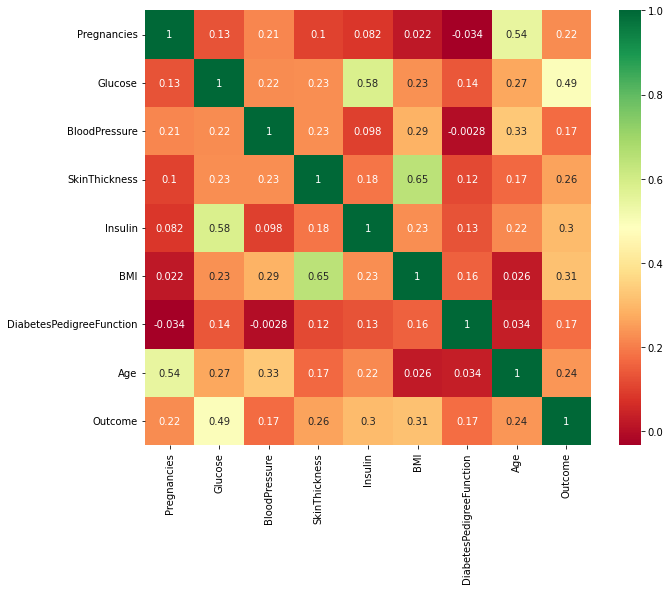

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

data_corr = data[['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age','Outcome']].corr()

plt.figure(figsize=(10,8))
sns.heatmap(data_corr, annot=True, cmap='RdYlGn')

### **Adaptive Iterative Imputation (AII) method for Missing Value Imputation**
The Adaptive Iterative Imputation method is an iterative approach to impute missing values in datasets. The method uses different imputation methods depending on the percentage of missing values for each variable. Specifically, the method uses KNN imputation for variables with less than 50% missing values and regression imputation for variables with more than 50% missing values.

The imputation process is performed iteratively until convergence or until the maximum number of iterations is reached. During each iteration, missing values for each variable are imputed using the appropriate imputation method. The imputed values for one variable can be used as predictors for imputing missing values in other variables.

The method is flexible and can be easily modified to use different imputation methods, depending on the characteristics of the data and the research question being addressed. However, the method assumes that missing values are missing at random and is sensitive to the choice of imputation methods.

Overall, the Adaptive Iterative Imputation method is a useful approach to imputing missing values in datasets, but its assumptions and limitations should be carefully considered, and sensitivity analyses should be performed to assess the robustness of the results to different imputation methods.

In [ ]:
# import required libraries
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
from sklearn.linear_model import LinearRegression

# define the adaptive iterative imputation function
def adaptive_iterative_impute(data, k_neighbors=5, max_iter=100, tol=1e-4):
    """
    This function performs adaptive iterative imputation on a dataset with missing values.
    The imputation method is KNN imputation for variables with less than 50% missing values,
    and regression imputation for variables with more than 50% missing values.
    The imputation process is performed iteratively until convergence or until the maximum number of iterations is reached.
    """
    # initialize the imputation method
    imputer = KNNImputer(n_neighbors=k_neighbors)

    # perform adaptive iterative imputation
    for i in range(max_iter):
        # determine the percentage of missing values for each variable
        missing_percentages = data.isnull().mean()

        # determine the variables with less than 50% missing values
        knn_vars = missing_percentages[missing_percentages < 0.5].index

        # determine the variables with more than 50% missing values
        reg_vars = missing_percentages[missing_percentages >= 0.5].index

        # impute missing values for variables with less than 50% missing values using KNN imputation
        for var in knn_vars:
            missing_idx = data[var].isnull()
            if missing_idx.any():
                imputed_values = imputer.fit_transform(data[var].values.reshape(-1, 1))
                data.loc[missing_idx, var] = imputed_values[missing_idx, 0]

        # impute missing values for variables with more than 50% missing values using regression imputation
        for var in reg_vars:
            # select the variables to use as predictors in the regression model
            predictors = data.loc[:, data.columns != var]
            missing_idx = data[var].isnull()
            if missing_idx.any():
                # fit a linear regression model to the observed data
                model = LinearRegression()
                model.fit(predictors[~missing_idx], data.loc[~missing_idx, var])
                # predict the missing values using the regression model
                data.loc[missing_idx, var] = model.predict(predictors[missing_idx])

        # check for convergence
        missing_values = data.isnull().sum().sum()
        if i > 0 and (prev_missing_values - missing_values) < tol:
            break
        prev_missing_values = missing_values

    return data

data = adaptive_iterative_impute(data)
data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101.0,76.0,48.00000,180.000000,32.9,0.171,63,0
764,2,122.0,70.0,27.00000,155.548223,36.8,0.340,27,0
765,5,121.0,72.0,23.00000,112.000000,26.2,0.245,30,0
766,1,126.0,60.0,29.15342,155.548223,30.1,0.349,47,1


### **Outlier Identification and Removal**

In [ ]:
import pandas as pd
from sklearn.ensemble import IsolationForest

def dynamic_ensemble_isolation_forest(df, window_size=1000, threshold=-0.5, ensemble_size=10):
    # Initialize the dynamic ensemble
    ensemble = []

    # Process the data in batches
    for i in range(0, len(df), window_size):

        # Extract the current window of data
        window_data = df[i:i+window_size]

        # Train a new Isolation Forest model on the current window
        model = IsolationForest(n_estimators=100, contamination=0.01)
        model.fit(window_data)

        # Add the new model to the ensemble
        ensemble.append(model)

        # Remove the oldest model if the ensemble size exceeds a certain threshold
        if len(ensemble) > ensemble_size:
            ensemble.pop(0)

        # Compute the outlier scores for the current window using the ensemble
        scores = ensemble[0].score_samples(window_data)
        for model in ensemble[1:]:
            scores += model.score_samples(window_data)
        scores /= len(ensemble)

        # Identify the outliers in the current window
        outliers = window_data[scores < threshold]
        outliers['score'] = scores[scores < threshold]

        # Remove the outliers from the current window
        window_data = window_data[scores >= threshold]

        # Update the threshold based on the outliers in the current window
        if len(outliers) > 0:
            threshold = outliers['score'].max()

        # Merge the current window back into the full dataset
        if i == 0:
            df_clean = window_data.copy()
        else:
            df_clean = pd.concat([df_clean, window_data])

    return df_clean

data_new = dynamic_ensemble_isolation_forest(data)
data_new

/usr/local/lib/python3.9/dist-packages/sklearn/base.py:420: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(
<ipython-input-43-9a4bb35ca9ba>:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outliers['score'] = scores[scores < threshold]


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
5,5,116.0,74.0,29.15342,155.548223,25.6,0.201,30,0
...,...,...,...,...,...,...,...,...,...
762,9,89.0,62.0,29.15342,155.548223,22.5,0.142,33,0
764,2,122.0,70.0,27.00000,155.548223,36.8,0.340,27,0
765,5,121.0,72.0,23.00000,112.000000,26.2,0.245,30,0
766,1,126.0,60.0,29.15342,155.548223,30.1,0.349,47,1


### **Class Balancing method**

<ipython-input-44-4c1691afce7e>:49: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  X = data_new.drop('Outcome',1)
/usr/local/lib/python3.9/dist-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(
/usr/local/lib/python3.9/dist-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


y_1 : [(0, 459), (1, 213)]
current_balance : 0.7547169811320755
y_2    : [(0, 240), (1, 318)]
current_balance : 0.9441624365482234
y_2    : [(0, 372), (1, 394)]
current_balance : 0.9847715736040609
y_2    : [(0, 388), (1, 394)]
current_balance : 1.0
y_2    : [(0, 395), (1, 395)]
y_3 : [(0, 395), (1, 395)]
Diabetes: 459
Non-Diabetes: 213
Diabetes (after resampling): (0, 395)
Non-Diabetes (after resampling): (1, 395)


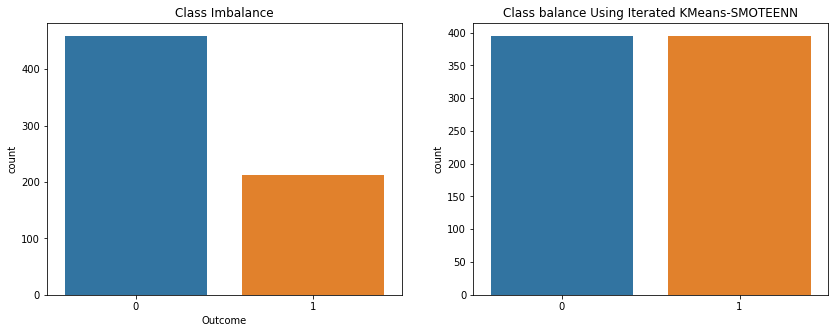

In [ ]:
from collections import Counter
import numpy as np
from sklearn.cluster import KMeans
from imblearn.combine import SMOTEENN

class IteratedKMeansSMOTEENN:
    def __init__(self, random_state=None, target_balance=1):
        self.random_state = random_state
        self.target_balance = target_balance

    def imbalance_ratio(self, y):
        counts = np.bincount(y)
        majority_class = np.argmax(counts)
        minority_count = counts[1 - majority_class]
        return minority_count / counts[majority_class]

    def kmeans_smoteenn(self, X, y, n_init=1):
        # perform k-means clustering on X
        kmeans = KMeans(n_clusters=2, n_init=n_init, random_state=self.random_state)
        labels = kmeans.fit_predict(X)
        # resample the data using SMOTEENN
        smoteenn = SMOTEENN(random_state=self.random_state)
        X_resampled, y_resampled = smoteenn.fit_resample(X[labels == 0], y[labels == 0])
        for label in np.unique(labels[labels != 0]):
            X_resampled_tmp, y_resampled_tmp = smoteenn.fit_resample(X[labels == label], y[labels == label])
            X_resampled = np.vstack((X_resampled, X_resampled_tmp))
            y_resampled = np.concatenate((y_resampled, y_resampled_tmp))
        return X_resampled, y_resampled

    def fit_resample(self, X, y):
        # initialize variables
        X_resampled = X
        y_resampled = y
        current_balance = self.imbalance_ratio(y_resampled)

        # keep iterating until desired balance is achieved
        while current_balance <= self.target_balance:
            # apply kmeans_smoteenn
            X_resampled, y_resampled = self.kmeans_smoteenn(X_resampled, y_resampled)
            # update current balance
            current_balance = self.imbalance_ratio(y_resampled)
            print("current_balance :",current_balance)
            print("y_2    :", sorted(Counter(y_resampled).items()))
            if current_balance == self.target_balance:
                break

        return X_resampled, y_resampled

X = data_new.drop('Outcome',1)
y = data_new['Outcome']

print("y_1 :", sorted(Counter(y).items()))
IKS = IteratedKMeansSMOTEENN()
X_resampled, y_resampled = IKS.fit_resample(X, y)
print("y_3 :", sorted(Counter(y_resampled).items()))

import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter

# plot the count of the target variable before resampling
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
ax = sns.countplot(y, label='Count', ax=axs[0])
ax.set_title('Class Imbalance')
B, M = y.value_counts()
print('Diabetes:', B)
print('Non-Diabetes:', M)

B1, M1 = Counter(y_resampled).items()
ax = sns.countplot(y_resampled, label='Count', ax=axs[1])
ax.set_title('Class balance Using Iterated KMeans-SMOTEENN')

print('Diabetes (after resampling):', B1)
print('Non-Diabetes (after resampling):', M1)

plt.show()

### **Classifier**

In [ ]:
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import cross_validate
import numpy as np

# Initialize classifiers and scoring metrics
HGBC = HistGradientBoostingClassifier()
ExTC = ExtraTreesClassifier()
RFC = RandomForestClassifier(n_estimators=100, random_state=42)
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1':'f1'}

# Perform cross-validation for each classifier and print results
for clf in [HGBC, ExTC, RFC]:
    scores = cross_validate(clf, X_resampled, y_resampled, cv=10, scoring=scoring)
    print(f'Score Matrices for {clf.__class__.__name__}:', scores.keys())
    print(f'{clf.__class__.__name__} Accuracy  : ', np.mean(scores['test_accuracy']))
    print(f'{clf.__class__.__name__} Precision : ', np.mean(scores['test_precision']))
    print(f'{clf.__class__.__name__} Recall    : ', np.mean(scores['test_recall']))
    print(f'{clf.__class__.__name__} F1-Score  : ', np.mean(scores['test_f1']))


Score Matrices for HistGradientBoostingClassifier: dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1'])
HistGradientBoostingClassifier Accuracy  :  0.9746835443037973
HistGradientBoostingClassifier Precision :  0.9805400696864112
HistGradientBoostingClassifier Recall    :  0.97
HistGradientBoostingClassifier F1-Score  :  0.972822231055124
Score Matrices for ExtraTreesClassifier: dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1'])
ExtraTreesClassifier Accuracy  :  0.9924050632911392
ExtraTreesClassifier Precision :  0.987857142857143
ExtraTreesClassifier Recall    :  0.9974999999999999
ExtraTreesClassifier F1-Score  :  0.992498827941866
Score Matrices for RandomForestClassifier: dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1'])
RandomForestClassifier Accuracy  :  0.9759493670886077
RandomForestClassifier Precision :  0.9709824090638044
RandomFores

Epoch 1/50
64/64 [==============================] - 1s 5ms/step - loss: 0.5970 - accuracy: 0.7532 - val_loss: 0.4972 - val_accuracy: 0.8671
Epoch 2/50
64/64 [==============================] - 0s 2ms/step - loss: 0.4414 - accuracy: 0.8655 - val_loss: 0.3711 - val_accuracy: 0.8861
Epoch 3/50
64/64 [==============================] - 0s 4ms/step - loss: 0.3354 - accuracy: 0.8797 - val_loss: 0.2853 - val_accuracy: 0.9051
Epoch 4/50
64/64 [==============================] - 0s 3ms/step - loss: 0.2689 - accuracy: 0.9066 - val_loss: 0.2291 - val_accuracy: 0.9114
Epoch 5/50
64/64 [==============================] - 0s 4ms/step - loss: 0.2281 - accuracy: 0.9146 - val_loss: 0.1916 - val_accuracy: 0.9620
Epoch 6/50
64/64 [==============================] - 0s 4ms/step - loss: 0.2003 - accuracy: 0.9272 - val_loss: 0.1636 - val_accuracy: 0.9557
Epoch 7/50
64/64 [==============================] - 0s 4ms/step - loss: 0.1797 - accuracy: 0.9320 - val_loss: 0.1482 - val_accuracy: 0.9684
Epoch 8/50
64/64 [==

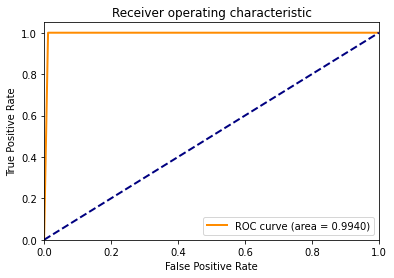

Accuracy : 0.9936708860759493
Precision: 0.9866666666666667
Recall   : 1.0
F1-score : 0.9932885906040269
AUC score: 0.9940476190476191


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import tensorflow as tf

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Scale the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Build the neural network model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(8,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=10, validation_data=(X_test, y_test))

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print('Test loss:', test_loss)
print('Test accuracy:', test_accuracy)

# Predict on the test set
y_pred = model.predict(X_test)
y_pred = (y_pred > 0.5).astype(int)

# Calculate accuracy, precision, recall, and F1-score
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Calculate ROC curve and AUC score
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.4f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()

# Print metrics
print('Accuracy :', accuracy)
print('Precision:', precision)
print('Recall   :', recall)
print('F1-score :', f1)
print('AUC score:', roc_auc)

## **Adaptive Extra Tree Classifier**
The code above is an implementation of the Adaptive Extra Tree Classifier because it dynamically adjusts the number of decision trees in the ensemble based on the performance on a validation set.

The fit method starts by creating an ensemble of decision trees with a minimum number of n_min trees. It then trains the ensemble on the training set and evaluates its performance on a validation set, if provided. If the error rate of the ensemble on the validation set is greater than the threshold error_threshold, the method increases the number of decision trees in the ensemble by n_min and repeats the process until either the maximum number of decision trees n_max is reached or the error rate on the validation set is below the threshold.

By dynamically adjusting the number of decision trees in the ensemble based on the validation set performance, the method creates an adaptive classifier that can balance model complexity and performance. If the classifier is overfitting, the method will reduce the number of trees in the ensemble, while if it is underfitting, the method will increase the number of trees in the ensemble. This adaptive behavior can lead to improved generalization performance and better model selection.

In [ ]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

class AdaptiveExtraTreeClassifier:
    def __init__(self, n_min=10, n_max=100, error_threshold=0.05, random_state=None):
        self.n_min = n_min
        self.n_max = n_max
        self.error_threshold = error_threshold
        self.random_state = random_state
        self.classifiers = []

    def fit(self, X, y, X_val=None, y_val=None):
        if self.random_state:
            np.random.seed(self.random_state)

        n_estimators = self.n_min
        error_rate = 1.0
        while n_estimators <= self.n_max and error_rate > self.error_threshold:
            classifiers = []
            for i in range(n_estimators):
                # Sample a random subset of the training data with replacement
                idx = np.random.choice(len(X), len(X), replace=True)
                X_sub, y_sub = X[idx], y[idx]

                # Train a decision tree on the subset of the data
                clf = DecisionTreeClassifier()
                clf.fit(X_sub, y_sub)
                classifiers.append(clf)

            self.classifiers.append(classifiers)
            if X_val is not None and y_val is not None:
                # Evaluate the ensemble on the validation set
                y_val_pred = self.predict(X_val)
                error_rate = np.sum(y_val_pred != y_val) / len(y_val)
            else:
                # Set the error rate to a large value if no validation set is provided
                error_rate = 1.0

            n_estimators += self.n_min

    def predict(self, X):
        y_pred = []
        for classifiers in self.classifiers:
            # Make a prediction using each decision tree in the ensemble
            y_pred_tree = np.array([clf.predict(X) for clf in classifiers])
            # Aggregate the predictions using majority voting
            y_pred_ensemble = np.apply_along_axis(lambda x: np.bincount(x).argmax(), axis=0, arr=y_pred_tree)
            y_pred.append(y_pred_ensemble)

        # Aggregate the predictions from all ensembles using majority voting
        y_pred = np.apply_along_axis(lambda x: np.bincount(x).argmax(), axis=0, arr=np.array(y_pred))
        return y_pred

    def get_params(self, deep=True):
        return {
                'n_min': self.n_min,
                'n_max': self.n_max,
                'error_threshold': self.error_threshold,
                'random_state': self.random_state
                }

    def set_params(self, **params):
        for param, value in params.items():
            setattr(self, param, value)
        return self
AETC = AdaptiveExtraTreeClassifier()
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1':'f1'}

scores = cross_validate(clf, X_resampled, y_resampled, cv=20, scoring=scoring)
print(f'Score Matrices for {clf.__class__.__name__}:', scores.keys())
print(f'{clf.__class__.__name__} Accuracy  : ', np.mean(scores['test_accuracy']))
print(f'{clf.__class__.__name__} Precision : ', np.mean(scores['test_precision']))
print(f'{clf.__class__.__name__} Recall    : ', np.mean(scores['test_recall']))
print(f'{clf.__class__.__name__} F1-Score  : ', np.mean(scores['test_f1']))

Score Matrices for RandomForestClassifier: dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1'])
RandomForestClassifier Accuracy  :  0.9784615384615385
RandomForestClassifier Precision :  0.9785497835497836
RandomForestClassifier Recall    :  0.9800000000000001
RandomForestClassifier F1-Score  :  0.9781451714025527


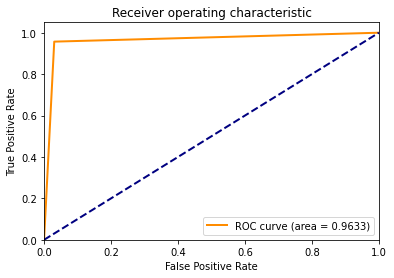

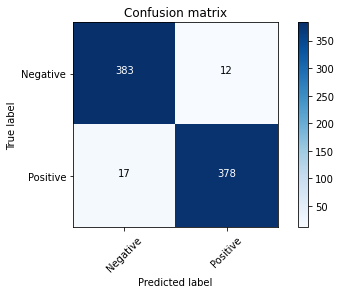

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, auc, confusion_matrix
from sklearn.linear_model import LogisticRegression

# Generate ROC curve using 5-fold cross-validation
cv = 20
y_pred = cross_val_predict(AETC, X_resampled,y_resampled, cv=cv)
fpr, tpr, _ = roc_curve(y_resampled, y_pred)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure()
lw = 2
plt.plot(fpr, tpr, color='darkorange',
         lw=lw, label='ROC curve (area = %0.4f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()

# Generate confusion matrix using 5-fold cross-validation
import itertools

cm = confusion_matrix(y_resampled, y_pred)

# Plot the confusion matrix
plt.figure()
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion matrix')
plt.colorbar()
tick_marks = np.arange(2)
plt.xticks(tick_marks, ['Negative', 'Positive'], rotation=45)
plt.yticks(tick_marks, ['Negative', 'Positive'])

# Add text values to the plot
thresh = cm.max() / 2.
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, format(cm[i, j], 'd'),
             horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black")

plt.tight_layout()
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()